# Noria · 04 — Model improvement (experiments E12 and E13)

Session 4, run **exactly** as pre-registered in `docs/experiments.md` (commit "Pre-register E12 and E13").

- **Preliminary decision**: `PHONE_CHANGE_YEARS` removed from every list (not verifiable by an Algerian advisor).
- **E12** — New deterministic features, LightGBM with vs without them, for the three lists.
- **E13** — Optuna tuning (50 trials per list, objective = mean 5-fold CV AUC on **train**), then E2 re-measured.

Models are fitted on train; metrics on validation. **The test set stays locked.**
The logic lives in `src/` (`experiments.py`, `train.py`, `tuning.py`, `evaluate.py`).

In [1]:
import sys
import json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, experiments, train as tr, evaluate as ev, tuning

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

def ci(d):
    return f"{d['auc_diff']:+.4f} [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]"

In [2]:
try:
    data.load_split("test")
except data.TestSetLockedError as error:
    print("As expected:", error)
train, val = data.load_train_val()
y_val = val[config.TARGET].to_numpy()
print(f"train rows: {len(train):,} · validation rows: {len(val):,}")
print("Feature lists now:", {k: len(v) for k, v in config.FEATURE_SETS.items()})
print("Non-transferable columns (never features):", config.NON_TRANSFERABLE_COLUMNS)

As expected: The test set is locked until the final evaluation. Use load_split('test', final=True) only for the final results.
train rows: 194,762 · validation rows: 41,735
Feature lists now: {'client': 7, 'bank_no_history': 52, 'bank_with_history': 65}
Non-transferable columns (never features): ['DAYS_LAST_PHONE_CHANGE', 'PHONE_CHANGE_YEARS']


## 1. E12 — New features

Bank candidates: `DOC_COUNT`, `CONTACT_COUNT`, `AGE_AT_EMPLOYMENT_START`, `CHILDREN_RATIO`, `ID_PUBLISH_AGE_RATIO`, `REGISTRATION_AGE_RATIO`.
Client candidates (computable from the public form): `AGE_AT_EMPLOYMENT_START`, `CHILDREN_RATIO`.
Rule: kept if the mean 5-fold CV AUC on train increases **and** the paired bootstrap CI on validation has a lower bound > 0.

In [3]:
e12, e12_models = experiments.run_e12(train, val)
e12_table = pd.DataFrame([
    {"list": name,
     "features ref → new": f"{r['reference']['n_features']} → {r['with_new']['n_features']}",
     "CV AUC ref": round(r["reference"]["cv_mean_auc"], 4), "CV AUC new": round(r["with_new"]["cv_mean_auc"], 4),
     "CV gain": round(r["cv_auc_gain"], 4),
     "val AUC ref": round(r["reference"]["val_auc"], 4), "val AUC new": round(r["with_new"]["val_auc"], 4),
     "val diff [95% CI]": ci(r["val_auc_diff"]), "decision": r["decision"]}
    for name, r in e12["lists"].items()
])
e12_table

,list,features ref → new,CV AUC ref,CV AUC new,CV gain,val AUC ref,val AUC new,val diff [95% CI],decision
0,bank_no_history,52 → 58,0.7005,0.6999,-0.0006,0.7058,0.7056,"-0.0002 [-0.0023, +0.0019]",dropped
1,bank_with_history,65 → 71,0.7615,0.7617,0.0002,0.7641,0.7652,"+0.0011 [-0.0003, +0.0027]",dropped
2,client,7 → 9,0.6190,0.6188,-0.0002,0.6189,0.6190,"+0.0001 [-0.0012, +0.0014]",dropped


In [4]:
final_lists = {name: r["final_features"] for name, r in e12["lists"].items()}
for name, feats in final_lists.items():
    assert feats == list(config.FEATURE_SETS[name]), f"{name}: config.FEATURE_SETS does not match the E12 decision"
print("Final lists after E12 (match config.FEATURE_SETS):", {k: len(v) for k, v in final_lists.items()})

Final lists after E12 (match config.FEATURE_SETS): {'bank_no_history': 52, 'bank_with_history': 65, 'client': 7}


,list,feature,share of gain (%),rank,of
0,bank_no_history,DOC_COUNT,1.45,15,147
1,bank_no_history,CONTACT_COUNT,0.55,24,147
2,bank_no_history,AGE_AT_EMPLOYMENT_START,2.67,12,147
3,bank_no_history,CHILDREN_RATIO,0.06,72,147
4,bank_no_history,ID_PUBLISH_AGE_RATIO,2.82,10,147
5,bank_no_history,REGISTRATION_AGE_RATIO,2.13,14,147
6,bank_with_history,DOC_COUNT,1.03,18,160
7,bank_with_history,CONTACT_COUNT,0.21,34,160
8,bank_with_history,AGE_AT_EMPLOYMENT_START,1.74,11,160
9,bank_with_history,CHILDREN_RATIO,0.04,78,160


Figure saved: reports/figures/11_e12_new_feature_importance.png


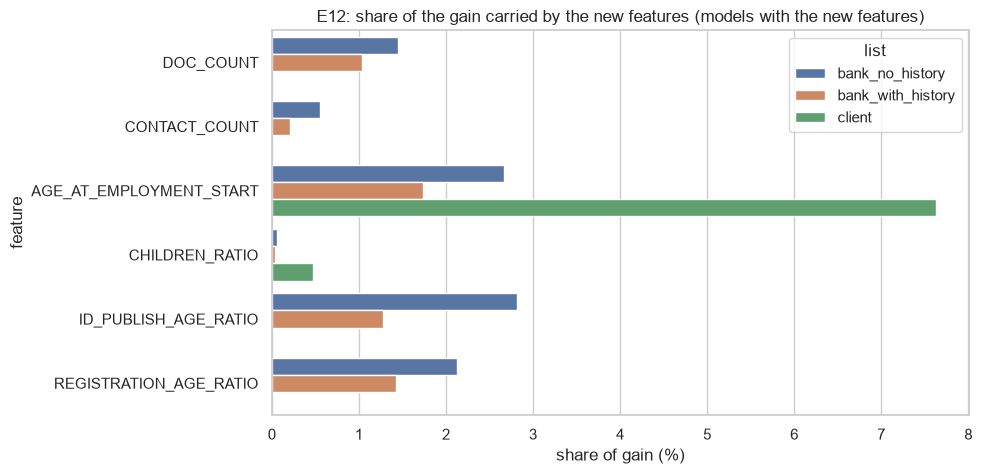

In [5]:
rows = []
for name, m in e12_models.items():
    gain = tr.feature_importance(m["with_new"]["pipeline"])
    share = gain / gain.sum() * 100
    rank = share.rank(ascending=False, method="min")
    for feat in e12["lists"][name]["candidates"]:
        rows.append({"list": name, "feature": feat, "share of gain (%)": round(share[feat], 2),
                     "rank": int(rank[feat]), "of": len(share)})
new_imp = pd.DataFrame(rows)
display(new_imp)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=new_imp, y="feature", x="share of gain (%)", hue="list", ax=ax)
ax.set_title("E12: share of the gain carried by the new features (models with the new features)")
save(fig, "11_e12_new_feature_importance.png")
plt.show()

## 2. E13 — Hyperparameter tuning (Optuna)

On the final lists from E12. 50 trials per list, TPE sampler (seed 42), objective = mean 5-fold CV AUC on train.
Rule: tuned parameters kept if their validation AUC is ≥ that of the default parameters.

In [6]:
e13, e13_models, studies = experiments.run_e13(train, val, e12_models)
e13_table = pd.DataFrame([
    {"list": name, "features": r["n_features"],
     "CV AUC default": round(r["default"]["cv_mean_auc"], 4),
     "CV AUC tuned": round(r["tuned"]["cv_mean_auc"], 4),
     "val AUC default": round(r["default"]["val_auc"], 4),
     "val AUC tuned": round(r["tuned"]["val_auc"], 4),
     "tuned - default [95% CI]": ci(r["val_auc_diff_tuned_minus_default"]),
     "trees default → tuned": f"{r['default']['n_estimators']} → {r['tuned']['n_estimators']}",
     "decision": r["decision"]}
    for name, r in e13["lists"].items()
])
e13_table

,list,features,CV AUC default,CV AUC tuned,val AUC default,val AUC tuned,tuned - default [95% CI],trees default → tuned,decision
0,bank_no_history,52,0.7005,0.7048,0.7058,0.7091,"+0.0033 [+0.0012, +0.0053]",242 → 392,tuned parameters kept
1,bank_with_history,65,0.7615,0.7640,0.7641,0.7663,"+0.0023 [+0.0008, +0.0038]",332 → 822,tuned parameters kept
2,client,7,0.6190,0.6206,0.6189,0.6207,"+0.0017 [-0.0001, +0.0035]",43 → 218,tuned parameters kept


In [7]:
params = pd.DataFrame({name: r["tuned"]["params"] for name, r in e13["lists"].items()})
params.loc[["num_leaves", "max_depth", "learning_rate", "min_child_samples", "subsample",
            "colsample_bytree", "reg_alpha", "reg_lambda"]]

,bank_no_history,bank_with_history,client
num_leaves,52,177,33
max_depth,11,5,3
learning_rate,0.025931,0.035601,0.041962
min_child_samples,426,332,41
subsample,0.912243,0.87683,0.749699
colsample_bytree,0.339125,0.401622,0.556635
reg_alpha,0.028289,0.025209,4.607455
reg_lambda,0.047398,0.00576,0.00252


Figure saved: reports/figures/12_optuna_history.png


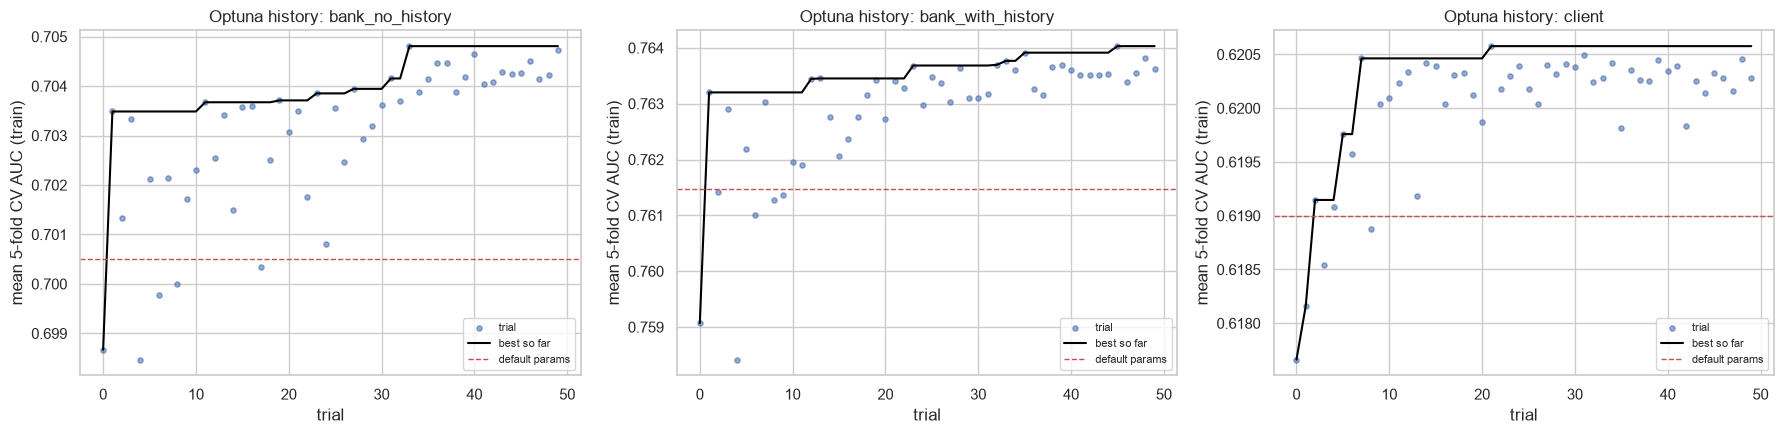

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, study) in zip(axes, studies.items()):
    t = tuning.trials_table(study)
    ax.scatter(t["number"], t["cv_auc"], s=14, alpha=0.6, label="trial")
    ax.plot(t["number"], t["cv_auc"].cummax(), color="black", lw=1.5, label="best so far")
    ax.axhline(e13["lists"][name]["default"]["cv_mean_auc"], color="#C44E52", ls="--", lw=1, label="default params")
    ax.set_title(f"Optuna history: {name}")
    ax.set_xlabel("trial")
    ax.set_ylabel("mean 5-fold CV AUC (train)")
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save(fig, "12_optuna_history.png")
plt.show()

## 3. E2 re-measured after E13 (cost of the history)

In [9]:
e2u = e13["e2_updated"]
e2_initial = json.loads((ev.METRICS_DIR / "e2.json").read_text())["with_minus_without"]
print(f"E2 initial (session 3, default params):  {ci(e2_initial)}")
print(f"E2 with the two tuned bank models:       {ci(e2u['tuned_models'])}")
print(f"   tuned with history {e2u['tuned_with_history_auc']:.4f} vs tuned without history {e2u['tuned_no_history_auc']:.4f}")
if "retained_models" in e2u:
    print(f"E2 with the retained (final) bank models: {ci(e2u['retained_models'])}")

E2 initial (session 3, default params):  +0.0569 [+0.0502, +0.0647]
E2 with the two tuned bank models:       +0.0572 [+0.0509, +0.0644]
   tuned with history 0.7663 vs tuned without history 0.7091


## 4. Before / after, step by step (validation)

Session 3 model → preliminary decision (`PHONE_CHANGE_YEARS` removed) → E12 → E13.
Each gain is a paired bootstrap difference on the validation set (1,000 resamples).

In [10]:
s3 = experiments.session3_predictions(train, val)
s3_key = {"bank_no_history": "lgbm__bank_no_history", "bank_with_history": "lgbm__bank_with_history",
          "client": "lgbm__client_no_pricing"}
rows = []
for name in ["bank_no_history", "bank_with_history", "client"]:
    p_s3 = s3[s3_key[name]]
    p_ref = e12_models[name]["reference"]["p_val"]
    p_e12 = e12_models[name]["final"]["p_val"]
    p_e13 = e13_models[name]["final"]["p_val"]
    auc = lambda p: ev.bootstrap_auc(y_val, p)["roc_auc"]
    rows.append({
        "list": name,
        "session 3": round(auc(p_s3), 4),
        "after preliminary decision": round(auc(p_ref), 4),
        "after E12": round(auc(p_e12), 4),
        "after E13 (final)": round(auc(p_e13), 4),
        "gain: preliminary decision": ci(ev.paired_bootstrap_auc_diff(y_val, p_ref, p_s3)),
        "gain: E12": ci(ev.paired_bootstrap_auc_diff(y_val, p_e12, p_ref)),
        "gain: E13": ci(ev.paired_bootstrap_auc_diff(y_val, p_e13, p_e12)),
        "total gain vs session 3": ci(ev.paired_bootstrap_auc_diff(y_val, p_e13, p_s3)),
    })
before_after = pd.DataFrame(rows).set_index("list")
ev.save_metrics(before_after.reset_index().to_dict(orient="records"), "session4_before_after")
before_after.T

list,bank_no_history,bank_with_history,client
session 3,0.7093,0.7663,0.6189
after preliminary decision,0.7058,0.7641,0.6189
after E12,0.7058,0.7641,0.6189
after E13 (final),0.7091,0.7663,0.6207
gain: preliminary decision,"-0.0036 [-0.0060, -0.0011]","-0.0022 [-0.0038, -0.0005]","+0.0000 [+0.0000, +0.0000]"
gain: E12,"+0.0000 [+0.0000, +0.0000]","+0.0000 [+0.0000, +0.0000]","+0.0000 [+0.0000, +0.0000]"
gain: E13,"+0.0033 [+0.0012, +0.0053]","+0.0023 [+0.0008, +0.0038]","+0.0017 [-0.0001, +0.0035]"
total gain vs session 3,"-0.0002 [-0.0030, +0.0027]","+0.0001 [-0.0016, +0.0017]","+0.0017 [-0.0001, +0.0035]"


## 5. Final models: overfitting check and top features

In [11]:
final_rows = []
for name, m in e13_models.items():
    met = m["final"]["metrics"]
    final_rows.append({"list": name, "features": met["n_features"], "train AUC": round(met["train_auc"], 4),
                       "CV AUC (train folds)": round(met["cv_mean_auc"], 4), "val AUC": round(met["roc_auc"], 4),
                       "train - val": round(met["train_minus_val_auc"], 4), "PR-AUC": round(met["pr_auc"], 4),
                       "top feature": met["top_feature"], "top share": round(met["top_feature_gain_share"], 4)})
pd.DataFrame(final_rows).set_index("list")

,features,train AUC,CV AUC (train folds),val AUC,train - val,PR-AUC,top feature,top share
list,,,,,,,,
bank_no_history,52,0.7629,0.7048,0.7091,0.0538,0.1933,CREDIT_TERM,0.2972
bank_with_history,65,0.8140,0.7640,0.7663,0.0477,0.2628,EXT_SOURCE_3,0.2110
client,7,0.6294,0.6206,0.6207,0.0088,0.1265,EMPLOYMENT_YEARS,0.3725


## Findings

All metrics on the validation set (41,735 rows); models fitted on train (194,762 rows). The test set stayed locked.

1. **Preliminary decision** (`PHONE_CHANGE_YEARS` removed, not verifiable by an Algerian advisor). Bank without history: 0.7093 → 0.7058, a paired difference of −0.0036 [−0.0060, −0.0011]. Bank with history: 0.7663 → 0.7641, −0.0022 [−0.0038, −0.0005]. The client model is unchanged (it never used the variable): 0.6189.
2. **E12 — New features: dropped for all three lists** (rule applied as written):
   - bank without history (52 → 58 features): CV AUC 0.7005 → 0.6999 (−0.0006); validation 0.7058 → 0.7056, −0.0002 [−0.0023, +0.0019];
   - bank with history (65 → 71): CV AUC 0.7615 → 0.7617 (+0.0002), but validation +0.0011 [−0.0003, +0.0027], whose lower bound is not > 0;
   - client (7 → 9): CV AUC 0.6190 → 0.6188 (−0.0002); validation +0.0001 [−0.0012, +0.0014].

   The final lists are unchanged: 52, 65 and 7 features.
3. **Weight of the new features** in the models that contained them: at most 2.82% of the gain in the bank models (`ID_PUBLISH_AGE_RATIO`, rank 10 of 147). In the client model, `AGE_AT_EMPLOYMENT_START` carries 7.63% (rank 5 of 17), without improving the AUC: it duplicates age and employment length. `CHILDREN_RATIO` carries almost nothing (≤ 0.47%).
4. **E13 — Tuning: tuned parameters kept for all three lists** (validation AUC ≥ default):
   - bank without history: CV 0.7005 → 0.7048; validation 0.7058 → **0.7091**, +0.0033 [+0.0012, +0.0053], 242 → 392 trees;
   - bank with history: CV 0.7615 → 0.7640; validation 0.7641 → **0.7663**, +0.0023 [+0.0008, +0.0038], 332 → 822 trees;
   - client: CV 0.6190 → 0.6206; validation 0.6189 → **0.6207**, +0.0017 [−0.0001, +0.0035], 43 → 218 trees. Its CI includes 0, but the E13 rule only requires validation AUC ≥ default.
5. **Best parameters** (saved in `reports/metrics/e13_best_params__*.json`): low learning rates (0.026-0.042), strong column subsampling (`colsample_bytree` 0.34-0.56), large `min_child_samples` for the bank models (426 and 332), shallow trees for the client model (`max_depth` 3) and for the bank model with history (`max_depth` 5).
6. **E2 re-measured with the two tuned bank models**: 0.7663 vs 0.7091, a gap of **+0.0572** [+0.0509, +0.0644] (initial E2: +0.0569 [+0.0502, +0.0647]). The cost of the history is stable.
7. **Session 4 net balance vs session 3**: bank without history −0.0002 [−0.0030, +0.0027], bank with history +0.0001 [−0.0016, +0.0017], client +0.0017 [−0.0001, +0.0035]. The tuning compensates exactly for the loss caused by removing `PHONE_CHANGE_YEARS`. The client model stays in the "stronger caution message" zone of E10 (0.6207 < 0.65).
8. **Overfitting check (final models)**: train AUC vs validation AUC is 0.7629 vs 0.7091 (gap 0.0538), 0.8140 vs 0.7640 (0.0477) and 0.6294 vs 0.6207 (0.0088). The CV AUC on train folds is close to the validation AUC for all three lists, so the validation estimates are consistent. The top features are `CREDIT_TERM` (29.72% of the gain), `EXT_SOURCE_3` (21.10%) and `EMPLOYMENT_YEARS` (37.25%), with no dominance or leak flag.